In [1]:
# %pip install pandas numpy matplotlib scikit-learn joblib
import os
os.environ["OMP_NUM_THREADS"] = "2"

from pathlib import Path
from time import perf_counter
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from threadpoolctl import threadpool_limits

pd.set_option("display.max_columns", 12)
RANDOM_STATE = 42
OUTPUT_DIR = Path("model_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

In [2]:
DATA_DIR = Path("prepared_data")
if not DATA_DIR.exists() and Path("../prepared_data").exists():
    DATA_DIR = Path("../prepared_data")
if not (DATA_DIR / "model_data.joblib").exists():
    raise FileNotFoundError("Run Step 1 first, or update DATA_DIR to your prepared_data folder.")

data = joblib.load(DATA_DIR / "model_data.joblib")
preprocessor = joblib.load(DATA_DIR / "preprocessor.joblib")
with open(DATA_DIR / "preparation_notes.json", encoding="utf-8") as file:
    preparation_notes = json.load(file)

X_train = data["X_train_ready"]
X_validation = data["X_validation_ready"]
y_train = data["y_train"].to_numpy()
y_validation = data["y_validation"].to_numpy()
train_meta = data["train_metadata"].reset_index(drop=True)
validation_meta = data["validation_metadata"].reset_index(drop=True)

split_rows = []
for split, key in [("Train", "train"), ("Validation", "validation"), ("Test — held out", "test")]:
    meta = data[f"{key}_metadata"]
    split_rows.append({"split": split, "rows": len(meta),
                       "forecast_start": meta["forecast_month"].min().date(),
                       "forecast_end": meta["forecast_month"].max().date()})
display(pd.DataFrame(split_rows))
assert train_meta["forecast_month"].max() < validation_meta["forecast_month"].min()
assert validation_meta["forecast_month"].max() < data["test_metadata"]["forecast_month"].min()
assert list(data["X_train"].columns) == data["feature_columns"]
assert "next_bill_amount" not in data["feature_columns"]
for split in ["train", "validation", "test", "latest"]:
    matrix = data[f"X_{split}_ready"]
    assert np.isfinite(matrix).all()
    assert matrix.shape[1] == len(data["encoded_feature_names"])
    if split != "latest":
        assert data[f"X_{split}"].index.equals(data[f"y_{split}"].index)
        assert data[f"X_{split}"].index.equals(data[f"{split}_metadata"].index)
print("Numeric inputs:", X_train.shape[1])
print("Scikit-learn version:", sklearn.__version__)

,split,rows,forecast_start,forecast_end
0,Train,10000,2024-02-01,2024-11-01
1,Validation,3000,2024-12-01,2025-02-01
2,Test — held out,3000,2025-03-01,2025-05-01


Numeric inputs: 25
Scikit-learn version: 1.7.2


Use clear error measures
- MAE: average absolute bill error, in the dataset's bill units. Lower is better. This selects the model.
- RMSE: gives larger errors more weight. Lower is better.
- WAPE: total absolute error divided by total actual bill amount, expressed as a percentage. Lower is better.
- R²: fit relative to predicting a constant mean; it can be negative. It is not an accuracy percentage.
The dataset does not specify currency. We do not assume rupees or dollars. Negative predictions are clipped to zero because all supplied bills are nonnegative.

In [3]:
def bill_predictions(model, inputs):
    return np.maximum(model.predict(inputs), 0)

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    denominator = np.abs(actual).sum()
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "WAPE_percent": 100 * np.abs(actual - predicted).sum() / denominator if denominator else np.nan,
        "R2": r2_score(actual, predicted) if len(actual) > 1 else np.nan,
    }

baseline_validation = {
    "Current bill": validation_meta["bill_amount"].to_numpy(),
    "Recent average": validation_meta["bill_mean_3"].to_numpy(),
}
baseline_results = pd.DataFrame([
    {"model": name, **calculate_metrics(y_validation, prediction)}
    for name, prediction in baseline_validation.items()
]).sort_values("MAE")
display(baseline_results.round(3))

,model,MAE,RMSE,WAPE_percent,R2
1,Recent average,56.473,85.087,10.885,0.822
0,Current bill,66.781,100.908,12.872,0.749


|model comparison

In [4]:
candidates = {
    "Training median": DummyRegressor(strategy="median"),
    "Ridge alpha=1": Ridge(alpha=1),
    "Ridge alpha=100": Ridge(alpha=100),
    "Random Forest leaf=2": RandomForestRegressor(
        n_estimators=200, min_samples_leaf=2, max_features=0.8,
        n_jobs=2, random_state=RANDOM_STATE),
    "Random Forest leaf=10": RandomForestRegressor(
        n_estimators=200, min_samples_leaf=10, max_features=1.0,
        n_jobs=2, random_state=RANDOM_STATE),
    "HistGradientBoosting 100": HistGradientBoostingRegressor(
        max_iter=100, learning_rate=0.1, max_leaf_nodes=15,
        l2_regularization=1, early_stopping=False, random_state=RANDOM_STATE),
    "HistGradientBoosting 250": HistGradientBoostingRegressor(
        max_iter=250, learning_rate=0.05, max_leaf_nodes=15,
        l2_regularization=1, early_stopping=False, random_state=RANDOM_STATE),
    "HistGradientBoosting 31 leaves": HistGradientBoostingRegressor(
        max_iter=200, learning_rate=0.05, max_leaf_nodes=31,
        l2_regularization=5, early_stopping=False, random_state=RANDOM_STATE),
}

fitted_models = {}
comparison_rows = []
for name, candidate in candidates.items():
    start = perf_counter()
    model = clone(candidate)
    with threadpool_limits(limits=2):
        model.fit(X_train, y_train)
        train_prediction = bill_predictions(model, X_train)
        prediction_start = perf_counter()
        validation_prediction = bill_predictions(model, X_validation)
        predict_seconds = perf_counter() - prediction_start
    elapsed = perf_counter() - start
    fitted_models[name] = model
    comparison_rows.append({
        "model": name,
        **calculate_metrics(y_validation, validation_prediction),
        "train_MAE": mean_absolute_error(y_train, train_prediction),
        "run_seconds": elapsed,
        "predict_3000_rows_seconds": predict_seconds,
    })
    print(f"{name}: validation MAE {comparison_rows[-1]['MAE']:.3f}; run {elapsed:.2f}s")

comparison = pd.DataFrame(comparison_rows).sort_values("MAE").reset_index(drop=True)
display(comparison.round(3))

Training median: validation MAE 150.481; run 0.07s
Ridge alpha=1: validation MAE 55.070; run 0.05s
Ridge alpha=100: validation MAE 54.257; run 0.03s
Random Forest leaf=2: validation MAE 50.054; run 11.54s
Random Forest leaf=10: validation MAE 49.213; run 8.84s
HistGradientBoosting 100: validation MAE 49.065; run 0.23s
HistGradientBoosting 250: validation MAE 48.999; run 0.47s
HistGradientBoosting 31 leaves: validation MAE 49.034; run 0.62s


,model,MAE,RMSE,WAPE_percent,R2,train_MAE,run_seconds,predict_3000_rows_seconds
0,HistGradientBoosting 250,48.999,78.639,9.444,0.848,43.605,0.471,0.024
1,HistGradientBoosting 31 leaves,49.034,78.808,9.451,0.847,41.085,0.616,0.029
2,HistGradientBoosting 100,49.065,79.071,9.457,0.846,44.463,0.231,0.012
3,Random Forest leaf=10,49.213,78.678,9.486,0.848,38.739,8.836,0.045
4,Random Forest leaf=2,50.054,78.995,9.648,0.846,22.430,11.543,0.056
5,Ridge alpha=100,54.257,79.045,10.458,0.846,51.220,0.027,0.000
6,Ridge alpha=1,55.070,79.185,10.615,0.846,51.150,0.047,0.000
7,Training median,150.481,207.148,29.005,-0.057,143.227,0.067,0.000


Freeze the choice before looking at test errors

Best trained candidate: HistGradientBoosting 250
Best practical baseline: Recent average
Validation MAE improvement over that baseline: 13.24%
Recommended forecast: HistGradientBoosting 250


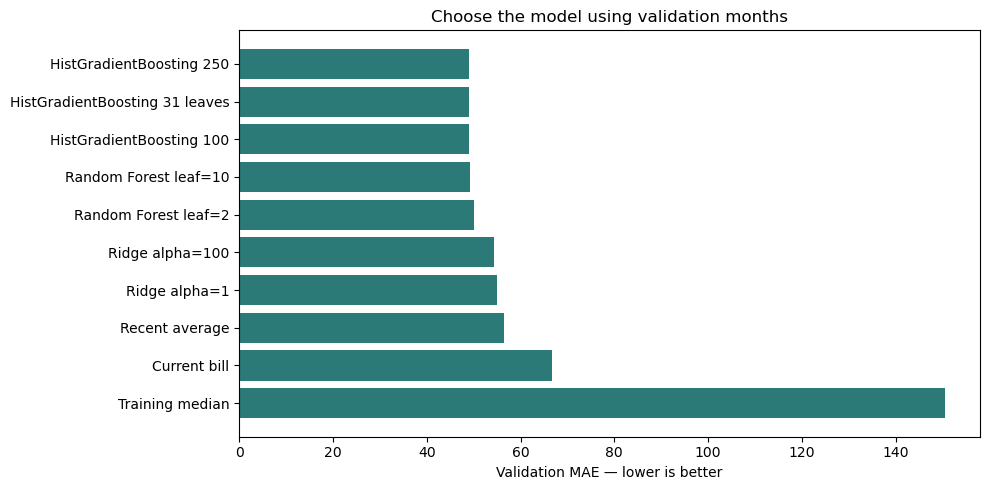

In [5]:
best_model_name = comparison.iloc[0]["model"]
selected_model = fitted_models[best_model_name]
best_baseline_name = baseline_results.iloc[0]["model"]
best_baseline_mae = float(baseline_results.iloc[0]["MAE"])
selected_mae = float(comparison.iloc[0]["MAE"])
use_baseline = selected_mae >= best_baseline_mae
recommended_name = best_baseline_name if use_baseline else best_model_name
validation_improvement = 100 * (best_baseline_mae - selected_mae) / best_baseline_mae

print("Best trained candidate:", best_model_name)
print("Best practical baseline:", best_baseline_name)
print(f"Validation MAE improvement over that baseline: {validation_improvement:.2f}%")
print("Recommended forecast:", recommended_name)

plot_data = pd.concat([comparison[["model", "MAE"]], baseline_results[["model", "MAE"]]])
plot_data = plot_data.sort_values("MAE", ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(plot_data["model"], plot_data["MAE"], color="#2b7a78")
ax.set_xlabel("Validation MAE — lower is better")
ax.set_title("Choose the model using validation months")
plt.tight_layout()
plt.show()

Inspect which raw inputs help the selected model

In [6]:
selection_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", selected_model),
])
# Score the same nonnegative forecasts used for model selection.
def negative_bill_mae(estimator, inputs, actual):
    return -mean_absolute_error(actual, bill_predictions(estimator, inputs))

sample_size = min(1000, len(data["X_validation"]))
positions = np.random.default_rng(RANDOM_STATE).choice(len(y_validation), sample_size, replace=False)
with threadpool_limits(limits=2):
    importance = permutation_importance(
        selection_pipeline, data["X_validation"].iloc[positions], y_validation[positions],
        scoring=negative_bill_mae, n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
feature_importance = pd.DataFrame({
    "feature": data["feature_columns"],
    "MAE_increase": importance.importances_mean,
    "repeat_std": importance.importances_std,
}).sort_values("MAE_increase", ascending=False)
display(feature_importance.head(10).round(3))

,feature,MAE_increase,repeat_std
14,bill_mean_3,108.960,0.943
17,usage_mean_3,9.971,0.892
10,tax_amount,4.136,0.175
5,plan_fee,3.461,0.180
1,data_usage_gb,3.210,0.255
7,data_charge,2.852,0.263
12,bill_lag_1,2.168,0.255
15,bill_std_3,2.159,0.324
4,addon_data_gb,1.666,0.141
16,bill_change_1,0.835,0.113


Refit the chosen model with all pre-test labels

In [7]:
X_development = np.vstack([X_train, X_validation])
y_development = np.concatenate([y_train, y_validation])
final_regressor = clone(candidates[best_model_name])
start = perf_counter()
with threadpool_limits(limits=2):
    final_regressor.fit(X_development, y_development)
final_fit_seconds = perf_counter() - start
final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", final_regressor),
])
print("Pre-test training rows:", len(y_development))
print(f"Final model fit: {final_fit_seconds:.2f}s")
print("Latest training target month:", validation_meta["forecast_month"].max().date())

Pre-test training rows: 13000
Final model fit: 0.38s
Latest training target month: 2025-02-01


Evaluate on the later test period

In [9]:
y_test = data["y_test"].to_numpy()
test_meta = data["test_metadata"].reset_index(drop=True)
with threadpool_limits(limits=2):
    selected_test_prediction = bill_predictions(final_pipeline, data["X_test"])
test_predictions_by_method = {
    best_model_name: selected_test_prediction,
    "Current bill": test_meta["bill_amount"].to_numpy(),
    "Recent average": test_meta["bill_mean_3"].to_numpy(),
}
test_results = pd.DataFrame([
    {"model": name, **calculate_metrics(y_test, prediction)}
    for name, prediction in test_predictions_by_method.items()
])
display(test_results.round(3))
recommended_test_prediction = test_predictions_by_method[recommended_name]
test_metrics = calculate_metrics(y_test, recommended_test_prediction)
test_baseline_mae = mean_absolute_error(y_test, test_predictions_by_method[best_baseline_name])
test_improvement = 100 * (test_baseline_mae - test_metrics["MAE"]) / test_baseline_mae
print("Recommendation stays fixed from validation:", recommended_name)
print(f"Test MAE improvement over validation-chosen baseline: {test_improvement:.2f}%")

test_output = test_meta.copy()
test_output["actual_next_bill"] = y_test
test_output["predicted_next_bill"] = recommended_test_prediction
test_output["current_bill_prediction"] = test_predictions_by_method["Current bill"]
test_output["recent_average_prediction"] = test_predictions_by_method["Recent average"]
test_output["error"] = recommended_test_prediction - y_test
test_output["absolute_error"] = np.abs(test_output["error"])
display(test_output.head().round(2))

,model,MAE,RMSE,WAPE_percent,R2
0,HistGradientBoosting 250,50.963,78.913,9.542,0.859
1,Current bill,69.306,105.682,12.976,0.747
2,Recent average,58.798,89.011,11.008,0.821


Recommendation stays fixed from validation: HistGradientBoosting 250
Test MAE improvement over validation-chosen baseline: 13.32%


,customer_id,billing_month,forecast_month,plan_type,bill_amount,bill_mean_3,...,actual_next_bill,predicted_next_bill,current_bill_prediction,recent_average_prediction,error,absolute_error
0,C00001,2025-02-01,2025-03-01,Standard,470.82,470.82,...,474.36,471.21,470.82,470.82,-3.15,3.15
1,C00001,2025-03-01,2025-04-01,Standard,474.36,472.00,...,441.32,479.85,474.36,472.00,38.53,38.53
2,C00001,2025-04-01,2025-05-01,Standard,441.32,462.17,...,444.27,469.48,441.32,462.17,25.21,25.21
3,C00002,2025-02-01,2025-03-01,Basic,234.82,201.58,...,234.82,257.51,234.82,201.58,22.69,22.69
4,C00002,2025-03-01,2025-04-01,Basic,234.82,215.15,...,234.82,248.41,234.82,215.15,13.59,13.59


Find weaker groups and larger mistakes

,segment,group,rows,MAE,RMSE,WAPE_percent,R2
0,plan_type,Basic,1233,74.098,105.063,16.726,0.782
1,plan_type,Premium,525,29.290,43.584,3.544,0.032
2,plan_type,Standard,1242,37.157,57.275,7.417,0.680
3,forecast_month,2025-03-01 00:00:00,1000,50.566,76.573,9.540,0.864
4,forecast_month,2025-04-01 00:00:00,1000,51.431,80.724,9.598,0.857
5,forecast_month,2025-05-01 00:00:00,1000,50.892,79.386,9.486,0.856
6,history_group,7+ months,3000,50.963,78.913,9.542,0.859
7,bill_range,Lower bills,999,54.972,66.981,16.639,0.362
8,bill_range,Middle bills,897,23.768,40.022,4.952,-2.918
9,bill_range,Higher bills,1104,69.431,107.522,9.106,0.459


,customer_id,billing_month,forecast_month,plan_type,bill_amount,bill_mean_3,...,current_bill_prediction,recent_average_prediction,error,absolute_error,history_group,bill_range
285,C00096,2025-02-01,2025-03-01,Basic,739.39,694.32,...,739.39,694.32,-474.55,474.55,7+ months,Higher bills
2912,C00971,2025-04-01,2025-05-01,Basic,565.03,605.33,...,565.03,605.33,-432.19,432.19,7+ months,Higher bills
403,C00135,2025-03-01,2025-04-01,Basic,744.47,701.55,...,744.47,701.55,-401.66,401.66,7+ months,Higher bills
2083,C00695,2025-03-01,2025-04-01,Basic,625.71,635.65,...,625.71,635.65,-399.88,399.88,7+ months,Higher bills
2533,C00845,2025-03-01,2025-04-01,Basic,522.58,560.63,...,522.58,560.63,-390.45,390.45,7+ months,Higher bills
533,C00178,2025-04-01,2025-05-01,Basic,750.68,722.58,...,750.68,722.58,-381.90,381.90,7+ months,Higher bills
1258,C00420,2025-03-01,2025-04-01,Basic,676.65,424.12,...,676.65,424.12,-376.63,376.63,7+ months,Higher bills
986,C00329,2025-04-01,2025-05-01,Basic,400.82,416.26,...,400.82,416.26,-372.70,372.70,7+ months,Higher bills
2454,C00819,2025-02-01,2025-03-01,Basic,638.48,616.14,...,638.48,616.14,-362.99,362.99,7+ months,Higher bills
1091,C00364,2025-04-01,2025-05-01,Basic,267.27,254.09,...,267.27,254.09,-353.42,353.42,7+ months,Higher bills


Absolute error percentiles:


0.50     31.82
0.90    119.23
0.95    158.94
0.99    313.58
Name: absolute_error, dtype: float64

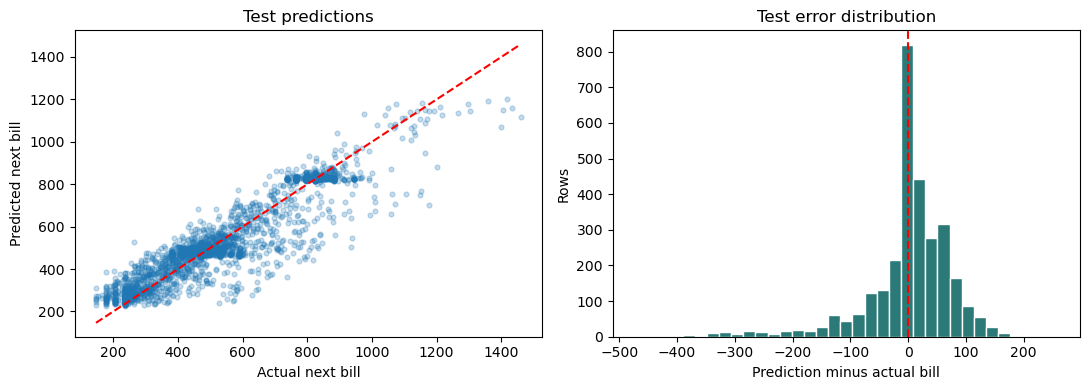

In [10]:
test_output["history_group"] = pd.cut(
    test_output["history_months"], bins=[0, 3, 6, np.inf],
    labels=["1–3 months", "4–6 months", "7+ months"])
q1, q2 = np.quantile(y_train, [1/3, 2/3])
test_output["bill_range"] = pd.cut(
    test_output["actual_next_bill"], bins=[-np.inf, q1, q2, np.inf],
    labels=["Lower bills", "Middle bills", "Higher bills"])

def group_errors(table, column):
    rows = []
    for group, part in table.groupby(column, observed=True):
        rows.append({"segment": column, "group": str(group), "rows": len(part),
                     **calculate_metrics(part["actual_next_bill"], part["predicted_next_bill"])})
    return pd.DataFrame(rows)

segment_results = pd.concat([
    group_errors(test_output, column)
    for column in ["plan_type", "forecast_month", "history_group", "bill_range"]
], ignore_index=True)
display(segment_results.round(3))
display(test_output.nlargest(10, "absolute_error").round(2))
print("Absolute error percentiles:")
display(test_output["absolute_error"].quantile([0.5, 0.9, 0.95, 0.99]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, recommended_test_prediction, alpha=0.25, s=12)
limits = [min(y_test.min(), recommended_test_prediction.min()),
          max(y_test.max(), recommended_test_prediction.max())]
axes[0].plot(limits, limits, "r--")
axes[0].set(xlabel="Actual next bill", ylabel="Predicted next bill", title="Test predictions")
axes[1].hist(test_output["error"], bins=35, color="#2b7a78", edgecolor="white")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set(xlabel="Prediction minus actual bill", ylabel="Rows", title="Test error distribution")
plt.tight_layout()
plt.show()

Generate the latest customer forecasts

In [11]:
latest_output = data["latest_metadata"].reset_index(drop=True).copy()
if use_baseline:
    baseline_column = "bill_amount" if recommended_name == "Current bill" else "bill_mean_3"
    latest_prediction = latest_output[baseline_column].to_numpy()
else:
    with threadpool_limits(limits=2):
        latest_prediction = bill_predictions(final_pipeline, data["X_latest"])
latest_output["predicted_next_bill"] = latest_prediction
latest_output["change_from_recent_average"] = latest_prediction - latest_output["bill_mean_3"]
latest_output["change_percent"] = (
    100 * latest_output["change_from_recent_average"] / latest_output["bill_mean_3"].replace(0, np.nan))
latest_output = latest_output.sort_values("change_from_recent_average", ascending=False)
display(latest_output.head(10).round(2))
print("Customer forecasts:", len(latest_output))

,customer_id,billing_month,forecast_month,plan_type,bill_amount,bill_mean_3,history_months,predicted_next_bill,change_from_recent_average,change_percent
728,C00729,2025-05-01,2025-06-01,Basic,435.94,460.67,17,540.80,80.12,17.39
955,C00956,2025-05-01,2025-06-01,Basic,257.85,219.04,17,294.86,75.82,34.61
933,C00934,2025-05-01,2025-06-01,Basic,791.88,746.42,17,820.66,74.24,9.95
447,C00448,2025-05-01,2025-06-01,Basic,164.68,220.89,17,295.09,74.21,33.60
178,C00179,2025-05-01,2025-06-01,Standard,448.35,433.26,17,504.41,71.16,16.42
625,C00626,2025-05-01,2025-06-01,Basic,175.82,167.90,17,237.79,69.89,41.63
736,C00737,2025-05-01,2025-06-01,Basic,364.14,354.81,17,423.05,68.24,19.23
123,C00124,2025-05-01,2025-06-01,Basic,316.52,300.42,17,368.63,68.21,22.70
639,C00640,2025-05-01,2025-06-01,Standard,924.77,799.32,17,867.27,67.96,8.50
580,C00581,2025-05-01,2025-06-01,Basic,951.55,887.96,17,955.08,67.11,7.56


Customer forecasts: 1000


Save the model, forecast rule and evaluation

In [12]:
forecast_bundle = {
    "pipeline": final_pipeline,
    "feature_columns": data["feature_columns"],
    "recommended_name": recommended_name,
    "use_baseline": bool(use_baseline),
    "baseline_column": ("bill_amount" if best_baseline_name == "Current bill" else "bill_mean_3"),
    "forecast_horizon": preparation_notes["forecast_horizon"],
    "history_rule": preparation_notes["history_rule"],
    "prediction_floor": 0.0,
}
joblib.dump(final_pipeline, OUTPUT_DIR / "best_model_pipeline.joblib")
joblib.dump(forecast_bundle, OUTPUT_DIR / "forecast_bundle.joblib")
comparison.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)
baseline_results.to_csv(OUTPUT_DIR / "validation_baselines.csv", index=False)
test_results.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
test_output.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
segment_results.to_csv(OUTPUT_DIR / "test_segment_metrics.csv", index=False)
feature_importance.to_csv(OUTPUT_DIR / "validation_feature_importance.csv", index=False)
latest_output.to_csv(OUTPUT_DIR / "latest_customer_predictions.csv", index=False)

summary = {
    "best_trained_candidate": best_model_name,
    "recommended_forecast": recommended_name,
    "selection_metric": "Lowest validation MAE; practical baseline wins if no trained candidate improves it",
    "selected_parameters": selected_model.get_params(),
    "validation_MAE": selected_mae,
    "best_baseline": best_baseline_name,
    "validation_improvement_percent": validation_improvement,
    "test_metrics_for_recommendation": test_metrics,
    "test_improvement_percent": test_improvement,
    "final_model_fit_seconds": final_fit_seconds,
    "train_target_end": preparation_notes["train_target_end"],
    "validation_target_end": preparation_notes["validation_target_end"],
    "test_target_end": preparation_notes["test_target_end"],
    "raw_features": data["feature_columns"],
    "final_fit_rows": len(y_development),
    "preprocessing": "Frozen from Step 1 training rows; regressor refitted on train plus validation",
    "versions": {"pandas": pd.__version__, "numpy": np.__version__, "scikit_learn": sklearn.__version__},
    "limitations": [
        "Synthetic-data results do not establish real-world accuracy.",
        "Only a small set of model settings and one validation window were tested.",
        "Existing-customer rolling one-month forecasts; not a new-customer evaluation.",
        "Annual seasonality cannot be established from this short history.",
        "Permutation importance is portfolio-level influence, not individual causal explanation.",
        "Prediction intervals, customer explanations and evaluated high-bill flags are the next stage.",
    ],
}
with open(OUTPUT_DIR / "model_summary.json", "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2)
print("Saved model and results to:", OUTPUT_DIR.resolve())

Saved model and results to: C:\Users\saipr\OneDrive\Desktop\HCL\model_outputs


Reload and check a prediction

In [13]:
saved = joblib.load(OUTPUT_DIR / "forecast_bundle.joblib")
new_inputs = data["X_latest"][saved["feature_columns"]].copy()
if saved["use_baseline"]:
    reloaded_prediction = new_inputs[saved["baseline_column"]].to_numpy()
else:
    with threadpool_limits(limits=2):
        reloaded_prediction = bill_predictions(saved["pipeline"], new_inputs)

np.testing.assert_allclose(reloaded_prediction, latest_prediction)
assert np.isfinite(reloaded_prediction).all()
assert (reloaded_prediction >= 0).all()
saved_test = pd.read_csv(OUTPUT_DIR / "test_predictions.csv")
np.testing.assert_allclose(saved_test["actual_next_bill"], y_test)
np.testing.assert_allclose(saved_test["predicted_next_bill"], recommended_test_prediction)
print("Reload check passed. Saved forecasts match.")
print("Recommended model:", recommended_name)
print(f"Test MAE: {test_metrics['MAE']:.3f}")
print(f"Test RMSE: {test_metrics['RMSE']:.3f}")
print(f"Test WAPE: {test_metrics['WAPE_percent']:.2f}%")

Reload check passed. Saved forecasts match.
Recommended model: HistGradientBoosting 250
Test MAE: 50.963
Test RMSE: 78.913
Test WAPE: 9.54%
